In [107]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor
import numpy as np
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer

In [108]:
df = pd.read_csv("project_risk_raw_dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (4000, 51)


,Project_ID,Project_Type,Team_Size,Project_Budget_USD,Estimated_Timeline_Months,Complexity_Score,Stakeholder_Count,Methodology_Used,Team_Experience_Level,Past_Similar_Projects,External_Dependencies_Count,Change_Request_Frequency,Project_Phase,Requirement_Stability,Team_Turnover_Rate,Vendor_Reliability_Score,Historical_Risk_Incidents,Communication_Frequency,Regulatory_Compliance_Level,Technology_Familiarity,Geographical_Distribution,Stakeholder_Engagement_Level,Schedule_Pressure,Budget_Utilization_Rate,Executive_Sponsorship,Funding_Source,Market_Volatility,Integration_Complexity,Resource_Availability,Priority_Level,Organizational_Change_Frequency,Cross_Functional_Dependencies,Previous_Delivery_Success_Rate,Technical_Debt_Level,Project_Manager_Experience,Org_Process_Maturity,Data_Security_Requirements,Key_Stakeholder_Availability,Tech_Environment_Stability,Contract_Type,Resource_Contention_Level,Industry_Volatility,Client_Experience_Level,Change_Control_Maturity,Risk_Management_Maturity,Team_Colocation,Documentation_Quality,Project_Start_Month,Current_Phase_Duration_Months,Seasonal_Risk_Factor,Risk_Level
0,PROJ_0001,Construction,32,1526276.55,32,9.70,16,Waterfall,Senior,3,3,1.05,Planning,Moderate,0.16,0.84,2,1.90,Medium,Expert,4,Medium,0.0,0.82,Moderate,Government,0.55,2.66,0.98,Medium,0.29,6,0.80,0.00,Mid-level PM,Managed,Medium,Limited,NaN,Time & Materials,High,Extreme,First-time,Basic,Basic,Fully Colocated,Good,10,5,1.0,High
1,PROJ_0002,Manufacturing,2,390790.15,9,2.72,9,Kanban,Mixed,0,2,2.61,Execution,Moderate,0.42,0.79,2,2.65,High,Familiar,5,Excellent,0.0,0.76,Weak,External,0.29,2.45,0.95,Low,0.50,3,0.73,0.00,Mid-level PM,Optimizing,Low,Excellent,NaN,Cost-Plus,Low,Stable,Occasional,Advanced,Formal,Fully Remote,Poor,9,3,1.0,Low
2,PROJ_0003,Manufacturing,2,246674.76,6,2.04,7,Agile,Mixed,1,0,0.83,Initiation,Stable,0.55,0.89,2,1.87,Medium,Familiar,3,Excellent,0.0,1.17,Strong,Internal,0.15,5.57,0.79,High,2.71,2,0.91,0.00,Mid-level PM,Ad-hoc,Medium,Moderate,NaN,Cost-Plus,High,Stable,Regular,None,None,Hybrid,Good,5,1,1.0,Medium
3,PROJ_0004,IT,12,1427830.63,17,7.54,16,Scrum,Mixed,0,5,2.42,Initiation,Moderate,0.33,0.84,1,1.36,Low,Familiar,5,Medium,0.1,0.73,Moderate,Mixed,0.74,7.49,0.52,Critical,0.74,5,0.71,0.43,Certified PM,Managed,Strict,Good,Mixed,Hybrid,High,Extreme,Strategic,Formal,Basic,Hybrid,Basic,12,6,1.1,High
4,PROJ_0005,Construction,24,1696746.64,24,6.68,17,Hybrid,Junior,0,2,0.16,Execution,Stable,0.36,0.86,1,1.02,Critical,Expert,2,Low,0.0,0.60,Moderate,Government,0.19,1.64,0.58,Medium,0.56,6,0.83,0.00,Certified PM,Defined,Medium,Moderate,NaN,Cost-Plus,High,Moderate,Occasional,Basic,None,Partially Colocated,Basic,9,6,1.0,High


In [56]:
import pandas as pd
import numpy as np
from scipy.stats import f_oneway, chi2_contingency

# 1️⃣ Identify numeric and categorical columns
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

# Exclude target column from features
target = "Risk_Level"
if target in numeric_cols:
    numeric_cols.remove(target)
if target in categorical_cols:
    categorical_cols.remove(target)

results = []

# 2️⃣ Numeric features vs numeric target (if target was numeric)
if df[target].dtype in ["int64", "float64"]:
    for col in numeric_cols:
        corr = df[col].corr(df[target], method="spearman")  # Spearman works better for ordinal
        results.append({"Feature": col, "Type": "Numeric", "Method": "Spearman", "Value": corr})

# 3️⃣ Numeric features vs categorical target (ANOVA)
if df[target].dtype == "object" or str(df[target].dtype).startswith("category"):
    for col in numeric_cols:
        groups = [df[df[target] == level][col].dropna() for level in df[target].unique()]
        if len(groups) > 1:
            f_stat, p_value = f_oneway(*groups)
            results.append({"Feature": col, "Type": "Numeric", "Method": "ANOVA (F-stat)", "Value": f_stat, "P-Value": p_value})

# 4️⃣ Categorical features vs categorical target (Chi-Square)
for col in categorical_cols:
    contingency_table = pd.crosstab(df[col], df[target])
    if contingency_table.shape[0] > 1:
        chi2, p_value, dof, expected = chi2_contingency(contingency_table)
        results.append({"Feature": col, "Type": "Categorical", "Method": "Chi-Square", "Value": chi2, "P-Value": p_value})

# 5️⃣ Combine results into a dataframe
correlation_summary = pd.DataFrame(results)
correlation_summary = correlation_summary.sort_values(by=["Type","Method","Value"], ascending=[True, True, False])

# 6️⃣ Show top features by relationship strength
print(correlation_summary)




                            Feature         Type          Method  \
25                       Project_ID  Categorical      Chi-Square   
38             Org_Process_Maturity  Categorical      Chi-Square   
28            Team_Experience_Level  Categorical      Chi-Square   
47         Risk_Management_Maturity  Categorical      Chi-Square   
46          Change_Control_Maturity  Categorical      Chi-Square   
32           Technology_Familiarity  Categorical      Chi-Square   
37       Project_Manager_Experience  Categorical      Chi-Square   
44              Industry_Volatility  Categorical      Chi-Square   
40     Key_Stakeholder_Availability  Categorical      Chi-Square   
33     Stakeholder_Engagement_Level  Categorical      Chi-Square   
26                     Project_Type  Categorical      Chi-Square   
43        Resource_Contention_Level  Categorical      Chi-Square   
41       Tech_Environment_Stability  Categorical      Chi-Square   
29                    Project_Phase  Categorical

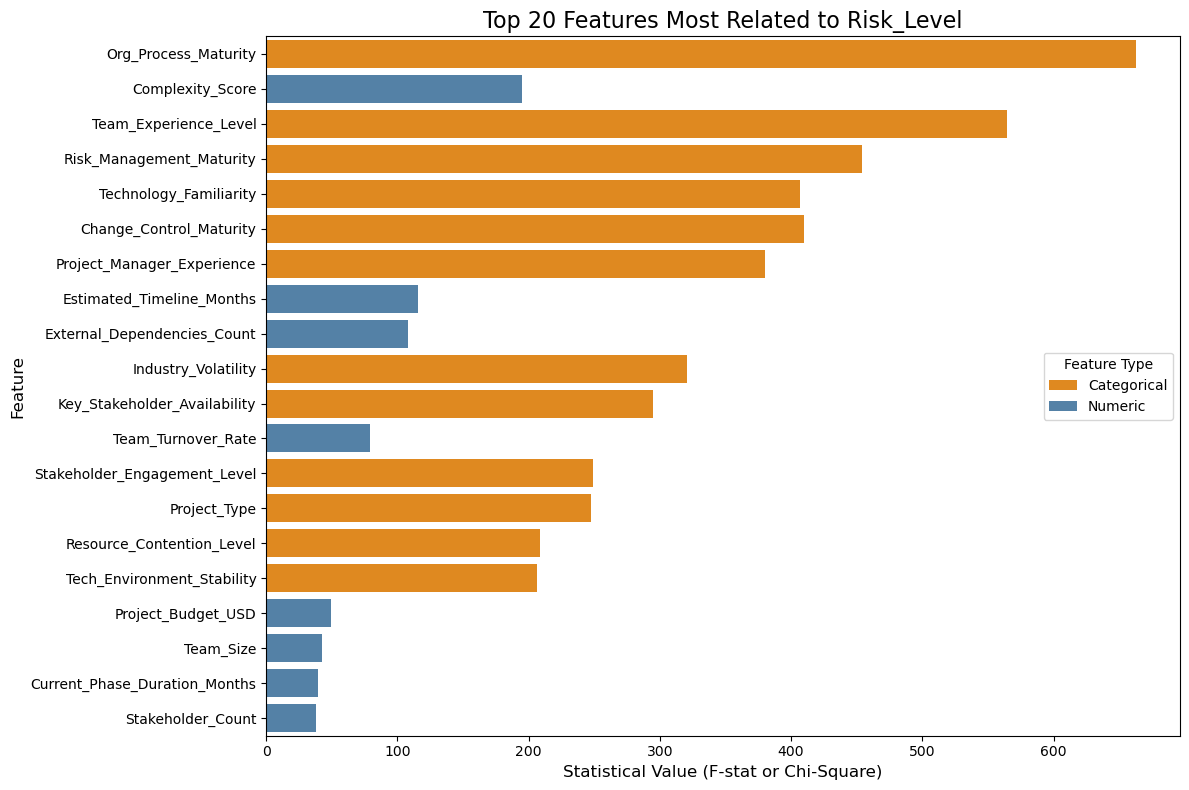

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assuming your correlation summary is in `correlation_summary` dataframe
# Sort by P-Value to get most significant features
top_features = correlation_summary.sort_values("P-Value").head(20)

# Set a color palette for feature type
palette = {"Numeric": "steelblue", "Categorical": "darkorange"}

plt.figure(figsize=(12,8))
sns.barplot(
    x="Value", 
    y="Feature", 
    data=top_features, 
    hue="Type", 
    dodge=False,  # so bars don't split
    palette=palette
)

plt.title("Top 20 Features Most Related to Risk_Level", fontsize=16)
plt.xlabel("Statistical Value (F-stat or Chi-Square)", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.legend(title="Feature Type")
plt.tight_layout()
plt.show()


In [58]:
df = df.drop(columns=["Methodology_Used","Vendor_Reliability_Score","Communication_Frequency","Regulatory_Compliance_Level","Geographical_Distribution","Integration_Complexity","Organizational_Change_Frequency","Cross_Functional_Dependencies","Technical_Debt_Level","Data_Security_Requirements","Contract_Type", "Team_Colocation","Seasonal_Risk_Factor"])
df = df.drop(columns=["Project_ID", "Client_Experience_Level", "Documentation_Quality"])
df = df.drop(columns=["Requirement_Stability","Funding_Source","Executive_Sponsorship"])

In [59]:
df = df.drop(columns=["Change_Request_Frequency","Stakeholder_Count","Past_Similar_Projects","Historical_Risk_Incidents","Schedule_Pressure","Market_Volatility"])

In [60]:
df=df.drop(columns=["Tech_Environment_Stability"])

In [61]:
df.head()

,Project_Type,Team_Size,Project_Budget_USD,Estimated_Timeline_Months,Complexity_Score,Team_Experience_Level,External_Dependencies_Count,Project_Phase,Team_Turnover_Rate,Technology_Familiarity,Stakeholder_Engagement_Level,Budget_Utilization_Rate,Resource_Availability,Priority_Level,Previous_Delivery_Success_Rate,Project_Manager_Experience,Org_Process_Maturity,Key_Stakeholder_Availability,Resource_Contention_Level,Industry_Volatility,Change_Control_Maturity,Risk_Management_Maturity,Project_Start_Month,Current_Phase_Duration_Months,Risk_Level
0,Construction,32,1526276.55,32,9.70,Senior,3,Planning,0.16,Expert,Medium,0.82,0.98,Medium,0.80,Mid-level PM,Managed,Limited,High,Extreme,Basic,Basic,10,5,High
1,Manufacturing,2,390790.15,9,2.72,Mixed,2,Execution,0.42,Familiar,Excellent,0.76,0.95,Low,0.73,Mid-level PM,Optimizing,Excellent,Low,Stable,Advanced,Formal,9,3,Low
2,Manufacturing,2,246674.76,6,2.04,Mixed,0,Initiation,0.55,Familiar,Excellent,1.17,0.79,High,0.91,Mid-level PM,Ad-hoc,Moderate,High,Stable,None,None,5,1,Medium
3,IT,12,1427830.63,17,7.54,Mixed,5,Initiation,0.33,Familiar,Medium,0.73,0.52,Critical,0.71,Certified PM,Managed,Good,High,Extreme,Formal,Basic,12,6,High
4,Construction,24,1696746.64,24,6.68,Junior,2,Execution,0.36,Expert,Low,0.60,0.58,Medium,0.83,Certified PM,Defined,Moderate,High,Moderate,Basic,None,9,6,High


In [62]:
null_counts = df.isna().sum().sort_values(ascending=False)
null_counts

Project_Type                      0
Priority_Level                    0
Current_Phase_Duration_Months     0
Project_Start_Month               0
Risk_Management_Maturity          0
Change_Control_Maturity           0
Industry_Volatility               0
Resource_Contention_Level         0
Key_Stakeholder_Availability      0
Org_Process_Maturity              0
Project_Manager_Experience        0
Previous_Delivery_Success_Rate    0
Resource_Availability             0
Team_Size                         0
Budget_Utilization_Rate           0
Stakeholder_Engagement_Level      0
Technology_Familiarity            0
Team_Turnover_Rate                0
Project_Phase                     0
External_Dependencies_Count       0
Team_Experience_Level             0
Complexity_Score                  0
Estimated_Timeline_Months         0
Project_Budget_USD                0
Risk_Level                        0
dtype: int64

In [63]:
# Show all columns in DataFrame display
pd.set_option("display.max_columns", None)

df.head()

,Project_Type,Team_Size,Project_Budget_USD,Estimated_Timeline_Months,Complexity_Score,Team_Experience_Level,External_Dependencies_Count,Project_Phase,Team_Turnover_Rate,Technology_Familiarity,Stakeholder_Engagement_Level,Budget_Utilization_Rate,Resource_Availability,Priority_Level,Previous_Delivery_Success_Rate,Project_Manager_Experience,Org_Process_Maturity,Key_Stakeholder_Availability,Resource_Contention_Level,Industry_Volatility,Change_Control_Maturity,Risk_Management_Maturity,Project_Start_Month,Current_Phase_Duration_Months,Risk_Level
0,Construction,32,1526276.55,32,9.70,Senior,3,Planning,0.16,Expert,Medium,0.82,0.98,Medium,0.80,Mid-level PM,Managed,Limited,High,Extreme,Basic,Basic,10,5,High
1,Manufacturing,2,390790.15,9,2.72,Mixed,2,Execution,0.42,Familiar,Excellent,0.76,0.95,Low,0.73,Mid-level PM,Optimizing,Excellent,Low,Stable,Advanced,Formal,9,3,Low
2,Manufacturing,2,246674.76,6,2.04,Mixed,0,Initiation,0.55,Familiar,Excellent,1.17,0.79,High,0.91,Mid-level PM,Ad-hoc,Moderate,High,Stable,None,None,5,1,Medium
3,IT,12,1427830.63,17,7.54,Mixed,5,Initiation,0.33,Familiar,Medium,0.73,0.52,Critical,0.71,Certified PM,Managed,Good,High,Extreme,Formal,Basic,12,6,High
4,Construction,24,1696746.64,24,6.68,Junior,2,Execution,0.36,Expert,Low,0.60,0.58,Medium,0.83,Certified PM,Defined,Moderate,High,Moderate,Basic,None,9,6,High


In [64]:
# Encode Risk_Level to numeric for correlation
risk_map = {"Low": 1, "Medium": 2, "High": 3, "Critical": 4}
df["Risk_Level_Numeric"] = df["Risk_Level"].map(risk_map)


In [65]:
df = df.drop("Risk_Level", axis=1)

In [66]:
# Show all remaining columns after dropping
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print("Remaining columns after dropping:")
print(df.columns.tolist())
print(f"\nTotal columns: {len(df.columns)}")
print(f"Shape: {df.shape}")

Remaining columns after dropping:
['Project_Type', 'Team_Size', 'Project_Budget_USD', 'Estimated_Timeline_Months', 'Complexity_Score', 'Team_Experience_Level', 'External_Dependencies_Count', 'Project_Phase', 'Team_Turnover_Rate', 'Technology_Familiarity', 'Stakeholder_Engagement_Level', 'Budget_Utilization_Rate', 'Resource_Availability', 'Priority_Level', 'Previous_Delivery_Success_Rate', 'Project_Manager_Experience', 'Org_Process_Maturity', 'Key_Stakeholder_Availability', 'Resource_Contention_Level', 'Industry_Volatility', 'Change_Control_Maturity', 'Risk_Management_Maturity', 'Project_Start_Month', 'Current_Phase_Duration_Months', 'Risk_Level_Numeric']

Total columns: 25
Shape: (4000, 25)


In [67]:
print(df.corr(numeric_only=True)["Risk_Level_Numeric"].sort_values(ascending=False))

Risk_Level_Numeric                1.000000
Complexity_Score                  0.350977
Estimated_Timeline_Months         0.278886
External_Dependencies_Count       0.266652
Team_Turnover_Rate                0.231981
Project_Budget_USD                0.185820
Team_Size                         0.170922
Current_Phase_Duration_Months     0.164627
Budget_Utilization_Rate           0.049738
Project_Start_Month              -0.002682
Resource_Availability            -0.092213
Previous_Delivery_Success_Rate   -0.161859
Name: Risk_Level_Numeric, dtype: float64


In [68]:
TARGET = "Risk_Level_Numeric"

y = df[TARGET]
X = df.drop(columns=["Risk_Level_Numeric"])

In [69]:
cat_cols = X.select_dtypes(include=["object"]).columns
num_cols = X.select_dtypes(include=["number"]).columns

print("Categorical columns:", list(cat_cols))
print("Numeric columns:", list(num_cols))


Categorical columns: ['Project_Type', 'Team_Experience_Level', 'Project_Phase', 'Technology_Familiarity', 'Stakeholder_Engagement_Level', 'Priority_Level', 'Project_Manager_Experience', 'Org_Process_Maturity', 'Key_Stakeholder_Availability', 'Resource_Contention_Level', 'Industry_Volatility', 'Change_Control_Maturity', 'Risk_Management_Maturity']
Numeric columns: ['Team_Size', 'Project_Budget_USD', 'Estimated_Timeline_Months', 'Complexity_Score', 'External_Dependencies_Count', 'Team_Turnover_Rate', 'Budget_Utilization_Rate', 'Resource_Availability', 'Previous_Delivery_Success_Rate', 'Project_Start_Month', 'Current_Phase_Duration_Months']


In [70]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [71]:
onehot_cols = ["Team_Experience_Level", "Project_Phase","Project_Type","Org_Process_Maturity","Key_Stakeholder_Availability","Change_Control_Maturity","Risk_Management_Maturity"]

ordinal_cols = [
    "Technology_Familiarity",
    "Priority_Level",
    "Resource_Contention_Level",
    "Stakeholder_Engagement_Level",
    "Project_Manager_Experience",
    "Industry_Volatility"
]

tech_order = ["New", "Familiar", "Expert"]
priority_order = ["Low", "Medium", "High", "Critical"]
resource_order = ["Low", "Medium", "High"]
stakeholder_order = ["Poor","Low", "Medium", "High", "Excellent"]
manager_order = ["Junior PM", "Mid-level PM", "Senior PM", "Certified PM"]
industry_order = ["Stable","Moderate", "High", "Extreme"]



In [72]:
# preprocess = ColumnTransformer(
#     transformers=[
#         ("onehot", OneHotEncoder(handle_unknown="ignore"), onehot_cols),
#         ("ordinal", OrdinalEncoder(categories=[
#             tech_order,
#             priority_order,
#             resource_order,
#             stakeholder_order,
#             manager_order,
#             industry_order
#         ]), ordinal_cols),
#     ],
#     remainder="passthrough"
# )
preprocess = ColumnTransformer(
    transformers=[
        ("onehot", OneHotEncoder(handle_unknown="ignore"), onehot_cols),
        ("ordinal", OrdinalEncoder(
            categories=[tech_order, priority_order, resource_order, stakeholder_order, manager_order, industry_order],
            handle_unknown='use_encoded_value', unknown_value=-1
        ), ordinal_cols),
    ],
    remainder="passthrough"
)

In [73]:
preprocess.fit(X_train)


ColumnTransformer(remainder='passthrough',
                  transformers=[('onehot',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['Team_Experience_Level', 'Project_Phase',
                                  'Project_Type', 'Org_Process_Maturity',
                                  'Key_Stakeholder_Availability',
                                  'Change_Control_Maturity',
                                  'Risk_Management_Maturity']),
                                ('ordinal',
                                 OrdinalEncoder(categories=[['New', 'Familiar',
                                                             'Expert'],
                                                            ['Low', 'Medium...
                                                             'High'],
                                                            ['Poor', 'Low',
                                                             'Medium', 'High',
                                                             'Excellent'],
                                                            ['Junior PM',
                                                             'Mid-level PM',
                                                             'Senior PM',
                                                             'Certified PM'],
                                                            ['Stable',
                                                             'Moderate', 'High',
                                                             'Extreme']],
                                                handle_unknown='use_encoded_value',
                                                unknown_value=-1),
                                 ['Technology_Familiarity', 'Priority_Level',
                                  'Resource_Contention_Level',
                                  'Stakeholder_Engagement_Level',
                                  'Project_Manager_Experience',
                                  'Industry_Volatility'])])

In [74]:
X_train_encoded = preprocess.transform(X_train)

In [75]:
X_test_encoded = preprocess.transform(X_test)

In [76]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(
    max_iter=2000,
    multi_class="multinomial",
    solver="lbfgs",
    random_state=42
)

clf.fit(X_train_encoded, y_train)

LogisticRegression(max_iter=2000, multi_class='multinomial', random_state=42)

In [77]:
model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("clf", clf)
])

In [78]:
# Predictions
y_pred = clf.predict(X_test_encoded)

# Probabilities for all classes
probs = clf.predict_proba(X_test_encoded)

In [79]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred, target_names=['Low', 'Medium', 'High', 'Critical'], digits=4))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

         Low     0.0000    0.0000    0.0000       161
      Medium     0.3488    1.0000    0.5171       279
        High     0.0000    0.0000    0.0000       207
    Critical     0.0000    0.0000    0.0000       153

    accuracy                         0.3488       800
   macro avg     0.0872    0.2500    0.1293       800
weighted avg     0.1216    0.3488    0.1804       800

Confusion matrix:
 [[  0 161   0   0]
 [  0 279   0   0]
 [  0 207   0   0]
 [  0 153   0   0]]


c:\Users\maria\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\maria\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\maria\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [80]:
print("Probability array shape:", probs.shape)
print("Min probability:", probs.min())
print("Max probability:", probs.max())
print("Mean probability:", probs.mean())

Probability array shape: (800, 4)
Min probability: 0.11029589979468678
Max probability: 0.4155622441986549
Mean probability: 0.25


In [81]:
import sys
print(sys.executable)

c:\Users\maria\anaconda3\python.exe


In [82]:
from xgboost import XGBClassifier

In [83]:
y_train=y_train-1
y_test=y_test-1

In [84]:

from sklearn.pipeline import Pipeline

xgb_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("clf", XGBClassifier(
        objective="multi:softprob",
        eval_metric="mlogloss",
        num_class=4,
        random_state=42,
        n_estimators=100,
 
    ))
])

xgb_model.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Team_Experience_Level',
                                                   'Project_Phase',
                                                   'Project_Type',
                                                   'Org_Process_Maturity',
                                                   'Key_Stakeholder_Availability',
                                                   'Change_Control_Maturity',
                                                   'Risk_Management_Maturity']),
                                                 ('ordinal',
                                                  OrdinalEncoder(categories=[['New',
                                                                              'Fami...
                               feature_types=None, gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=None, num_class=4,
                               num_parallel_tree=None, ...))])

In [85]:
probs = xgb_model.predict_proba(X_test)
print(probs[:10])
print("Minimum probability:", probs.min())
print("Maximum probability:", probs.max())

[[1.19653549e-02 1.58002406e-01 8.15736890e-01 1.42953983e-02]
 [3.31173651e-04 1.83665350e-01 5.07021487e-01 3.08981955e-01]
 [1.56978250e-01 8.38889003e-01 1.18102948e-03 2.95177684e-03]
 [5.27866825e-04 4.63464223e-02 3.89441311e-01 5.63684404e-01]
 [1.82779878e-02 3.63753706e-01 4.78698373e-01 1.39269888e-01]
 [2.74665445e-01 6.85667217e-01 2.35269908e-02 1.61403250e-02]
 [4.84798111e-05 4.50497307e-03 1.23074405e-01 8.72372091e-01]
 [4.45385054e-02 3.54613215e-01 5.94938397e-01 5.90988947e-03]
 [1.81621872e-05 1.98736251e-03 6.83817267e-02 9.29612756e-01]
 [3.47193587e-03 1.40770838e-01 7.54625142e-01 1.01132050e-01]]
Minimum probability: 2.5674524e-08
Maximum probability: 0.99933016


Confusion Matrix:
[[109  48   4   0]
 [ 30 169  66  14]
 [  6  71  94  36]
 [  1  15  49  88]]


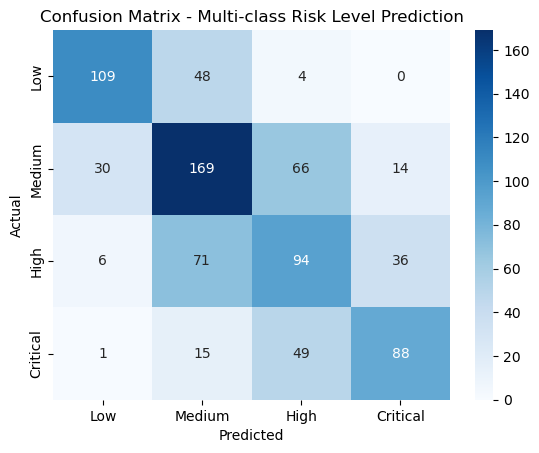

In [86]:
# Get predictions (direct class labels for multi-class)
y_pred = xgb_model.predict(X_test)

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0,1,2,3])
print("Confusion Matrix:")
print(cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=['Low', 'Medium', 'High', 'Critical'], yticklabels=['Low', 'Medium', 'High', 'Critical'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Multi-class Risk Level Prediction")
plt.show()

In [87]:
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report

print("Precision:", precision_score(y_test, y_pred, average="weighted"))
print("Recall:", recall_score(y_test, y_pred, average="weighted"))
print("F1-score:", f1_score(y_test, y_pred, average="weighted"))
print("Classification Report:\n", classification_report(y_test, y_pred))

Precision: 0.580912276988107
Recall: 0.575
F1-score: 0.576937357581805
Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.68      0.71       161
           1       0.56      0.61      0.58       279
           2       0.44      0.45      0.45       207
           3       0.64      0.58      0.60       153

    accuracy                           0.57       800
   macro avg       0.60      0.58      0.59       800
weighted avg       0.58      0.57      0.58       800



In [88]:
from lightgbm import LGBMClassifier

In [89]:
lgb_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("clf", LGBMClassifier(
        objective="multiclass",
        num_class=4,
        metric="multi_logloss",
        random_state=42,
        n_estimators=100,
        learning_rate=0.1,
        verbosity=-1
    ))
])

lgb_model.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Team_Experience_Level',
                                                   'Project_Phase',
                                                   'Project_Type',
                                                   'Org_Process_Maturity',
                                                   'Key_Stakeholder_Availability',
                                                   'Change_Control_Maturity',
                                                   'Risk_Management_Maturity']),
                                                 ('ordinal',
                                                  OrdinalEncoder(categories=[['New',
                                                                              'Fami...
                                                                              'Moderate',
                                                                              'High',
                                                                              'Extreme']],
                                                                 handle_unknown='use_encoded_value',
                                                                 unknown_value=-1),
                                                  ['Technology_Familiarity',
                                                   'Priority_Level',
                                                   'Resource_Contention_Level',
                                                   'Stakeholder_Engagement_Level',
                                                   'Project_Manager_Experience',
                                                   'Industry_Volatility'])])),
                ('clf',
                 LGBMClassifier(metric='multi_logloss', num_class=4,
                                objective='multiclass', random_state=42,
                                verbosity=-1))])

In [90]:
y_pred_lgb = lgb_model.predict(X_test)
probs_lgb = lgb_model.predict_proba(X_test)

print("LightGBM Predictions:")
print(probs_lgb[:10])
print("Min probability:", probs_lgb.min())
print("Max probability:", probs_lgb.max())

LightGBM Predictions:
[[1.03357633e-02 2.73169378e-01 6.69464154e-01 4.70307051e-02]
 [2.00879266e-03 2.04526745e-01 6.34152326e-01 1.59312136e-01]
 [6.08884245e-01 3.81895103e-01 1.44457705e-03 7.77607526e-03]
 [3.67863852e-03 4.21761802e-02 4.49476817e-01 5.04668365e-01]
 [2.65703903e-02 4.09633444e-01 4.39371356e-01 1.24424809e-01]
 [2.95602451e-01 6.30372471e-01 4.95409569e-02 2.44841209e-02]
 [1.11332828e-03 2.94498172e-02 1.64376734e-01 8.05060121e-01]
 [7.02096792e-02 5.47663527e-01 3.69105543e-01 1.30212509e-02]
 [5.00350064e-04 1.65748629e-02 1.33439486e-01 8.49485301e-01]
 [6.84589470e-03 4.56526592e-01 3.17580141e-01 2.19047373e-01]]
Min probability: 3.8766373570693213e-05
Max probability: 0.9919853839408717


LightGBM Confusion Matrix:
[[ 98  61   2   0]
 [ 32 176  62   9]
 [  4  83  87  33]
 [  1  12  58  82]]


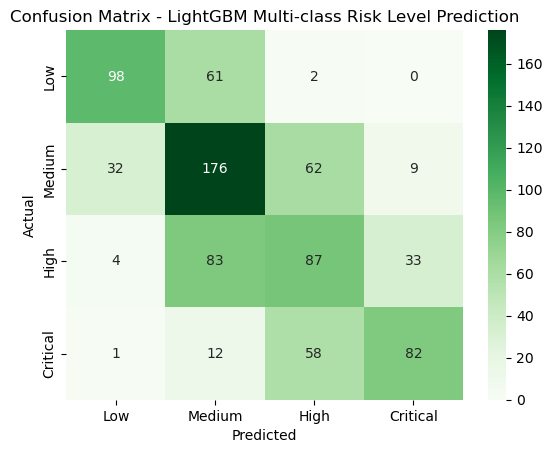

In [91]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm_lgb = confusion_matrix(y_test, y_pred_lgb, labels=[0, 1, 2, 3])
print("LightGBM Confusion Matrix:")
print(cm_lgb)

sns.heatmap(cm_lgb, annot=True, fmt="d", cmap="Greens", 
            xticklabels=['Low', 'Medium', 'High', 'Critical'], 
            yticklabels=['Low', 'Medium', 'High', 'Critical'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - LightGBM Multi-class Risk Level Prediction")
plt.show()

In [92]:
print("LightGBM Model Performance:")
print("Precision:", precision_score(y_test, y_pred_lgb, average="weighted"))
print("Recall:", recall_score(y_test, y_pred_lgb, average="weighted"))
print("F1-score:", f1_score(y_test, y_pred_lgb, average="weighted"))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lgb, 
                                                          target_names=['Low', 'Medium', 'High', 'Critical'], 
                                                          digits=4))

LightGBM Model Performance:
Precision: 0.5651532150019708
Recall: 0.55375
F1-score: 0.555634875806314

Classification Report:
               precision    recall  f1-score   support

         Low     0.7259    0.6087    0.6622       161
      Medium     0.5301    0.6308    0.5761       279
        High     0.4163    0.4203    0.4183       207
    Critical     0.6613    0.5359    0.5921       153

    accuracy                         0.5537       800
   macro avg     0.5834    0.5489    0.5621       800
weighted avg     0.5652    0.5537    0.5556       800



In [93]:
print("\n" + "="*60)
print("MODEL COMPARISON SUMMARY")
print("="*60)
print("\nLogisticRegression vs XGBoost vs LightGBM:")
print(f"Logistic Regression F1: {f1_score(y_test, model.predict(X_test), average='weighted'):.4f}")
print(f"XGBoost F1: {f1_score(y_test, y_pred, average='weighted'):.4f}")
print(f"LightGBM F1: {f1_score(y_test, y_pred_lgb, average='weighted'):.4f}")


MODEL COMPARISON SUMMARY

LogisticRegression vs XGBoost vs LightGBM:
Logistic Regression F1: 0.1064
XGBoost F1: 0.5769
LightGBM F1: 0.5556


TARGET VARIABLE DISTRIBUTION (BEFORE Y_TRAIN/Y_TEST SPLIT)

Value Counts:
1     806
2    1396
3    1036
4     762
Name: Risk_Level_Numeric, dtype: int64

Percentage Distribution:
  Low (1): 20.15%
  Medium (2): 34.9%
  High (3): 25.9%
  Critical (4): 19.05%


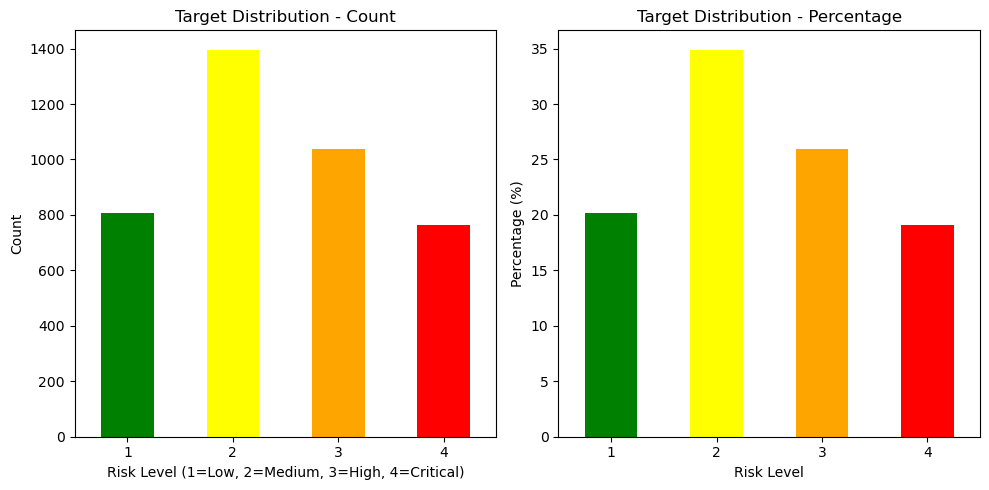

In [94]:
print("="*60)
print("TARGET VARIABLE DISTRIBUTION (BEFORE Y_TRAIN/Y_TEST SPLIT)")
print("="*60)

# Load fresh y from df to show original distribution
y_original = df["Risk_Level_Numeric"]
value_counts = y_original.value_counts().sort_index()
print("\nValue Counts:")
print(value_counts)

print("\nPercentage Distribution:")
percentage_dist = (value_counts / len(y_original) * 100).round(2)
for idx, pct in percentage_dist.items():
    risk_labels = {1: "Low", 2: "Medium", 3: "High", 4: "Critical"}
    print(f"  {risk_labels[idx]} ({idx}): {pct}%")

# Visualize distribution
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
value_counts.plot(kind='bar', color=['green', 'yellow', 'orange', 'red'])
plt.title("Target Distribution - Count")
plt.xlabel("Risk Level (1=Low, 2=Medium, 3=High, 4=Critical)")
plt.ylabel("Count")
plt.xticks(rotation=0)

plt.subplot(1, 2, 2)
percentage_dist.plot(kind='bar', color=['green', 'yellow', 'orange', 'red'])
plt.title("Target Distribution - Percentage")
plt.xlabel("Risk Level")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [95]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Reset y_train and y_test to original values (not -1)
y_train_reg = df.loc[X_train.index, "Risk_Level_Numeric"]
y_test_reg = df.loc[X_test.index, "Risk_Level_Numeric"]

print("\n1️⃣ LINEAR REGRESSION")
print("-" * 60)
linear_reg = Pipeline(steps=[
    ("preprocess", preprocess),
    ("reg", LinearRegression())
])

linear_reg.fit(X_train, y_train_reg)
y_pred_linear = linear_reg.predict(X_test)

mae_linear = mean_absolute_error(y_test_reg, y_pred_linear)
mse_linear = mean_squared_error(y_test_reg, y_pred_linear)
rmse_linear = np.sqrt(mse_linear)
r2_linear = r2_score(y_test_reg, y_pred_linear)

print(f"MAE: {mae_linear:.4f}")
print(f"MSE: {mse_linear:.4f}")
print(f"RMSE: {rmse_linear:.4f}")
print(f"R² Score: {r2_linear:.4f}")


1️⃣ LINEAR REGRESSION
------------------------------------------------------------
MAE: 0.5013
MSE: 0.3933
RMSE: 0.6272
R² Score: 0.6187


In [96]:
print("\n2️⃣ RANDOM FOREST REGRESSOR")
print("-" * 60)
rf_reg = Pipeline(steps=[
    ("preprocess", preprocess),
    ("reg", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

rf_reg.fit(X_train, y_train_reg)
y_pred_rf = rf_reg.predict(X_test)

mae_rf = mean_absolute_error(y_test_reg, y_pred_rf)
mse_rf = mean_squared_error(y_test_reg, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test_reg, y_pred_rf)

print(f"MAE: {mae_rf:.4f}")
print(f"MSE: {mse_rf:.4f}")
print(f"RMSE: {rmse_rf:.4f}")
print(f"R² Score: {r2_rf:.4f}")


2️⃣ RANDOM FOREST REGRESSOR
------------------------------------------------------------
MAE: 0.5734
MSE: 0.4855
RMSE: 0.6968
R² Score: 0.5293


In [97]:
print("\n3️⃣ XGBOOST REGRESSOR")
print("-" * 60)
xgb_reg = Pipeline(steps=[
    ("preprocess", preprocess),
    ("reg", XGBRegressor(
        n_estimators=100,
        random_state=42,
        learning_rate=0.1,
        max_depth=5
    ))
])

xgb_reg.fit(X_train, y_train_reg)
y_pred_xgb = xgb_reg.predict(X_test)

mae_xgb = mean_absolute_error(y_test_reg, y_pred_xgb)
mse_xgb = mean_squared_error(y_test_reg, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)
r2_xgb = r2_score(y_test_reg, y_pred_xgb)

print(f"MAE: {mae_xgb:.4f}")
print(f"MSE: {mse_xgb:.4f}")
print(f"RMSE: {rmse_xgb:.4f}")
print(f"R² Score: {r2_xgb:.4f}")


3️⃣ XGBOOST REGRESSOR
------------------------------------------------------------
MAE: 0.5030
MSE: 0.3872
RMSE: 0.6222
R² Score: 0.6246


In [98]:
print("\n4️⃣ LIGHTGBM REGRESSOR")
print("-" * 60)
lgb_reg = Pipeline(steps=[
    ("preprocess", preprocess),
    ("reg", LGBMRegressor(
        n_estimators=100,
        random_state=42,
        learning_rate=0.1,
        verbosity=-1
    ))
])

lgb_reg.fit(X_train, y_train_reg)
y_pred_lgb_reg = lgb_reg.predict(X_test)

mae_lgb = mean_absolute_error(y_test_reg, y_pred_lgb_reg)
mse_lgb = mean_squared_error(y_test_reg, y_pred_lgb_reg)
rmse_lgb = np.sqrt(mse_lgb)
r2_lgb = r2_score(y_test_reg, y_pred_lgb_reg)

print(f"MAE: {mae_lgb:.4f}")
print(f"MSE: {mse_lgb:.4f}")
print(f"RMSE: {rmse_lgb:.4f}")
print(f"R² Score: {r2_lgb:.4f}")


4️⃣ LIGHTGBM REGRESSOR
------------------------------------------------------------
MAE: 0.4877
MSE: 0.3742
RMSE: 0.6118
R² Score: 0.6371


In [99]:
print("\n" + "="*60)
print("REGRESSION MODELS COMPARISON")
print("="*60)

# Create comparison dataframe
regression_results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest', 'XGBoost', 'LightGBM'],
    'MAE': [mae_linear, mae_rf, mae_xgb, mae_lgb],
    'MSE': [mse_linear, mse_rf, mse_xgb, mse_lgb],
    'RMSE': [rmse_linear, rmse_rf, rmse_xgb, rmse_lgb],
    'R² Score': [r2_linear, r2_rf, r2_xgb, r2_lgb]
})

print("\n", regression_results.to_string(index=False))
print("\n✅ Best Model by R² Score:", regression_results.loc[regression_results['R² Score'].idxmax(), 'Model'])
print("✅ Best Model by RMSE:", regression_results.loc[regression_results['RMSE'].idxmin(), 'Model'])


REGRESSION MODELS COMPARISON

             Model      MAE      MSE     RMSE  R² Score
Linear Regression 0.501265 0.393323 0.627155  0.618651
    Random Forest 0.573438 0.485481 0.696764  0.529299
          XGBoost 0.503005 0.387179 0.622237  0.624608
         LightGBM 0.487728 0.374248 0.611758  0.637146

✅ Best Model by R² Score: LightGBM
✅ Best Model by RMSE: LightGBM


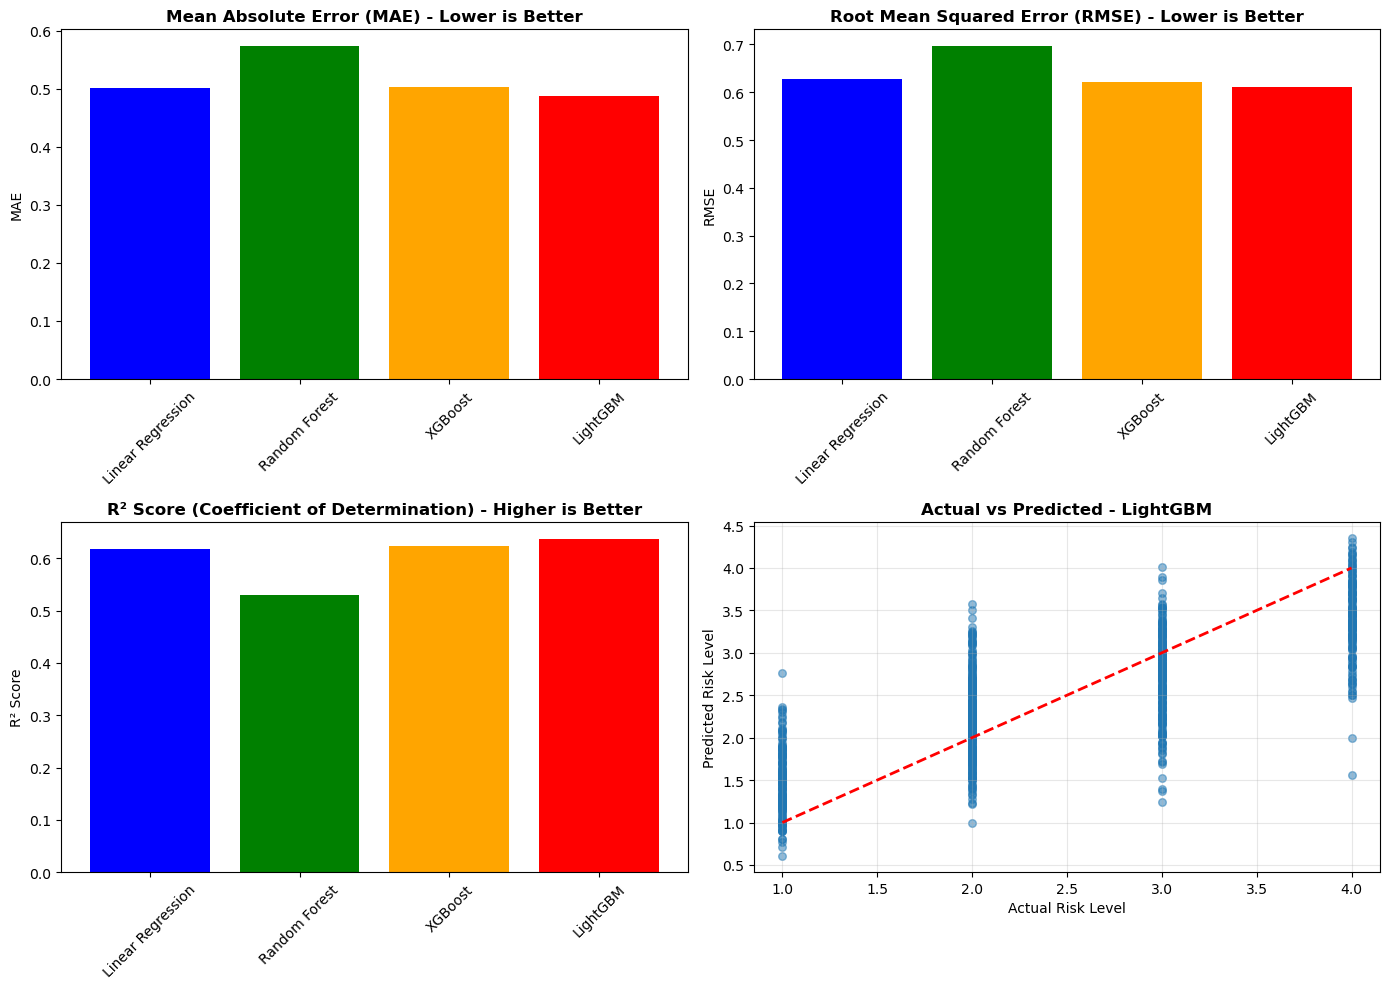

In [100]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

metrics = ['MAE', 'MSE', 'RMSE', 'R² Score']
reg_results_data = regression_results[['Model', 'MAE', 'MSE', 'RMSE', 'R² Score']]

# Plot 1: MAE Comparison
axes[0, 0].bar(regression_results['Model'], regression_results['MAE'], color=['blue', 'green', 'orange', 'red'])
axes[0, 0].set_title('Mean Absolute Error (MAE) - Lower is Better', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('MAE')
axes[0, 0].tick_params(axis='x', rotation=45)

# Plot 2: RMSE Comparison
axes[0, 1].bar(regression_results['Model'], regression_results['RMSE'], color=['blue', 'green', 'orange', 'red'])
axes[0, 1].set_title('Root Mean Squared Error (RMSE) - Lower is Better', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('RMSE')
axes[0, 1].tick_params(axis='x', rotation=45)

# Plot 3: R² Score Comparison
axes[1, 0].bar(regression_results['Model'], regression_results['R² Score'], color=['blue', 'green', 'orange', 'red'])
axes[1, 0].set_title('R² Score (Coefficient of Determination) - Higher is Better', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('R² Score')
axes[1, 0].axhline(y=0, color='black', linestyle='--', linewidth=0.5)
axes[1, 0].tick_params(axis='x', rotation=45)

# Plot 4: Predictions vs Actual (Best Model)
best_model_idx = regression_results['R² Score'].idxmax()
best_predictions = [y_pred_linear, y_pred_rf, y_pred_xgb, y_pred_lgb_reg][best_model_idx]
best_model_name = regression_results.loc[best_model_idx, 'Model']

axes[1, 1].scatter(y_test_reg, best_predictions, alpha=0.5, s=30)
axes[1, 1].plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2)
axes[1, 1].set_xlabel('Actual Risk Level')
axes[1, 1].set_ylabel('Predicted Risk Level')
axes[1, 1].set_title(f'Actual vs Predicted - {best_model_name}', fontsize=12, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [101]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class Weights:", class_weights)

Class Weights: {0: 1.2403100775193798, 1: 0.7162041181736795, 2: 0.9650180940892642, 3: 1.3136288998357963}


In [102]:
sample_weights = y_train.map(class_weights)

In [103]:
xgb_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("clf", XGBClassifier(
        objective="multi:softprob",
        eval_metric="mlogloss",
        n_estimators=600,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.85,
        colsample_bytree=0.85,
        random_state=42
    ))
])

xgb_model.fit(
    X_train,
    y_train,
    clf__sample_weight=sample_weights
)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Team_Experience_Level',
                                                   'Project_Phase',
                                                   'Project_Type',
                                                   'Org_Process_Maturity',
                                                   'Key_Stakeholder_Availability',
                                                   'Change_Control_Maturity',
                                                   'Risk_Management_Maturity']),
                                                 ('ordinal',
                                                  OrdinalEncoder(categories=[['New',
                                                                              'Fami...
                               feature_types=None, gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=600, n_jobs=None,
                               num_parallel_tree=None,
                               objective='multi:softprob', ...))])

In [104]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = xgb_model.predict(X_test)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, digits=4))
print("Precision:", precision_score(y_test, y_pred, average="weighted"))
print("Recall:", recall_score(y_test, y_pred , average="weighted"))
print("F1-score:", f1_score(y_test, y_pred , average="weighted"))

[[111  48   2   0]
 [ 41 163  61  14]
 [  3  70  91  43]
 [  1  10  46  96]]
              precision    recall  f1-score   support

           0     0.7115    0.6894    0.7003       161
           1     0.5601    0.5842    0.5719       279
           2     0.4550    0.4396    0.4472       207
           3     0.6275    0.6275    0.6275       153

    accuracy                         0.5763       800
   macro avg     0.5885    0.5852    0.5867       800
weighted avg     0.5763    0.5763    0.5761       800

Precision: 0.5762763035289453
Recall: 0.57625
F1-score: 0.5761054003265941


Exporting to CSV

In [105]:
df_features = df.drop(columns=[TARGET])

df_features.to_csv("features_only.csv", index=False)

In [106]:
import joblib

# Save the XGBoost classifier pipeline
joblib.dump(xgb_model, "risk_prediction_model.pkl")

['risk_prediction_model.pkl']